# TOP

In [1]:
# Standard
import os
import pandas as pd
import numpy as np


#Plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib as mpl


from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

#Scikit-learn
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import MinMaxScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Local functions
from Jakesdecomp import evaluate_components, bootstrap_features
import PLS_utils as utils


# Plotting functions
# Keep text editable in AI
mpl.rcParams['pdf.fonttype'] = 42 # embed TrueType fonts in PDF
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none' # write <text> in SVG (not paths)

# Directories MacOS
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'

# Directories Windows
#main_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\Top_sets\\Set309'
#core_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\_core_data'

fig_dir = os.path.join(main_dir, 'PLS_figures')
if not os.path.exists(fig_dir):
    os.makedirs(fig_dir)
files_dir = os.path.join(main_dir, '_set_data')
if not os.path.exists(files_dir):
    os.makedirs(files_dir)
    

plsset = '309'

In [2]:
# Global color palette
COLORS = {
    "c1_green": "#1AAB9B", 
    "c2_purple": "#521AAB",
    "male_blue":   "#2C6DB2",
    "female_red": "#D1495B",}

In [3]:
pheno_file = os.path.join(core_dir, 'pheno_filt_touse.xlsx')
train_file = os.path.join(main_dir , '_set_data/Clusters_train_PLS_bypval.csv')
test_file = os.path.join(main_dir, '_set_data/Clusters_test_PLS_bypval.csv')

train_data = pd.read_csv(train_file, index_col='projid')
test_data = pd.read_csv(test_file, index_col='projid')
phenotype_data = pd.read_excel(pheno_file, index_col='projid')
# Ensure both have the same column order
#test_data = test_data[train_data.columns]


# PLS Set309 (train)

## Prep data

In [4]:
pheno = phenotype_data[phenotype_data.index.isin(train_data.index)]

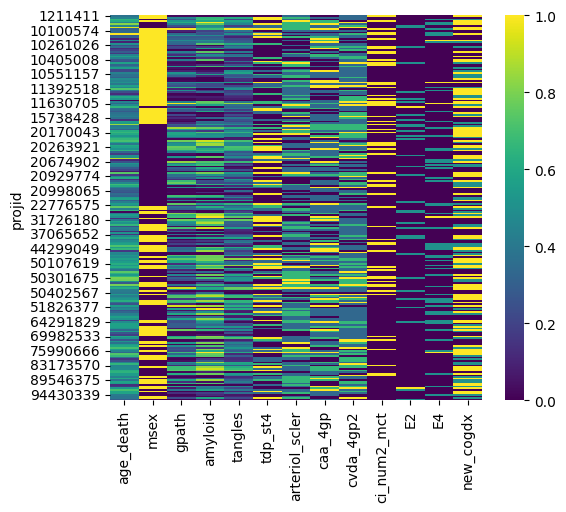

In [6]:
gene_filter_threshold=0.7
pheno_cols_drop = ['ad_reagan', 'ci_num2_gct', 'niareagansc', 'braaksc', 'ceradsc', 'nft']

train_minmax, gene_scaler, gene_imputer = utils.impute_minmax_genes(train_data)
pheno_minmax, pheno_scaler, pheno_imputer = utils.impute_minmax_pheno(phenotype_data, train_minmax, pheno_cols_drop=pheno_cols_drop)

## PLS and evaluation

In [7]:
#make sure the data indexes are alligned
x_genes_train = pd.DataFrame(train_minmax, copy=True)
y_pheno_train = pd.DataFrame(pheno_minmax, copy=True)
x_genes_train, y_pheno_train = x_genes_train.align(y_pheno_train, join='inner', axis=0)

Testing 1 components...
Testing 2 components...
Testing 3 components...
Testing 4 components...
Testing 5 components...
Testing 6 components...
Testing 7 components...
Testing 8 components...
Testing 9 components...
Testing 10 components...


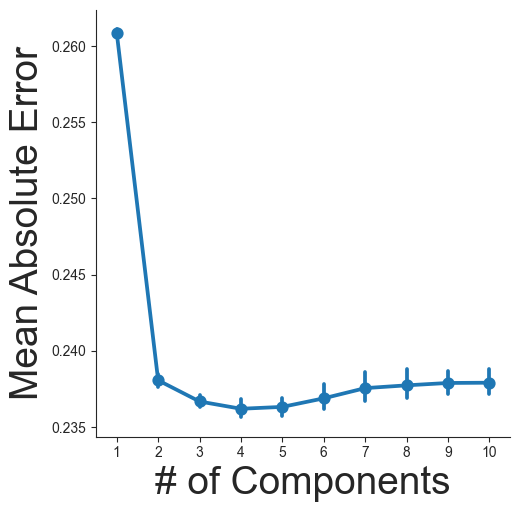

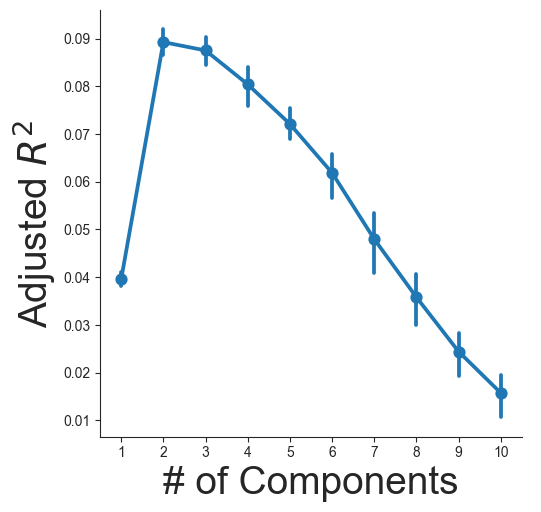

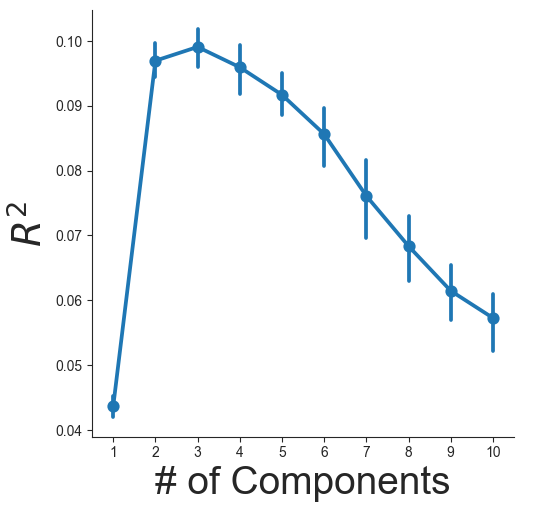

In [8]:
x_genes = x_genes_train.copy()
y_pheno = y_pheno_train.copy()
x_genes, y_pheno = x_genes.align(y_pheno, join='inner', axis=0)

n = x_genes.shape[0]  # number of samples
ncs=10
# Create results DataFrame
nc_chooser = pd.DataFrame(index=range(ncs * 10), columns=['nc', 'r2', 'adj_r2', 'mae', 'iter'])
i = 0

# Loop over component counts for PLSR only
for nc in range(1, ncs + 1):
    print(f"Testing {nc} components...")
    
    estimator = PLSRegression(n_components=nc)
    
    for it in range(10):  # 10 iterations of cross-validation
        cv = KFold(5, shuffle=True, random_state=123 + it)
        
        # cross-validation prediction
        pred = cross_val_predict(estimator, x_genes, y_pheno, cv=cv)
        
        # calculate normal CV R2
        r2 = r2_score(y_true=y_pheno, y_pred=pred)
        # calculate adjusted CV R2
        adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - nc - 1))
        
        # Store performance metrics
        nc_chooser.loc[i, 'r2'] = r2
        nc_chooser.loc[i, 'adj_r2'] = adj_r2
        nc_chooser.loc[i, 'mae'] = mean_absolute_error(y_true=y_pheno, y_pred=pred)
        nc_chooser.loc[i, 'nc'] = nc
        nc_chooser.loc[i, 'iter'] = it
        i += 1
        
# Set style and font for plots
#sns.set(font_scale=1.5)
sns.set_style('ticks')

# Plot MAE by the number of components
sns.catplot(x='nc', y='mae', data=nc_chooser, aspect=1, kind='point')
plt.ylabel('Mean Absolute Error', fontsize=28)
plt.xlabel('# of Components', fontsize=28)
#plt.ylim(0.2, 0.3)  # Adjust based on the MAE range in your data
plt.savefig(os.path.join(fig_dir, f'{plsset}_MAE_by_ncomponents.pdf'), dpi=300)
plt.show()


# Plot R2 by the number of components
sns.catplot(x='nc', y='adj_r2', data=nc_chooser, aspect=1, kind='point')
plt.ylabel(r'Adjusted $R^2$', fontsize=28)
plt.xlabel('# of Components', fontsize=28)  # Adjust based on the R² range in your data
plt.savefig(os.path.join(fig_dir, f'{plsset}_adjR2_by_ncomponents.pdf'), dpi=300)
plt.show()

# Plot R² by the number of components
sns.catplot(x='nc', y='r2', data=nc_chooser, aspect=1, kind='point')
plt.ylabel(r'$R^2$', fontsize=28)
plt.xlabel('# of Components', fontsize=28)  # Adjust based on the R² range in your data
plt.savefig(os.path.join(fig_dir, f'{plsset}_R2_by_ncomponents.pdf'), dpi=300)
plt.show()

<Figure size 500x400 with 0 Axes>

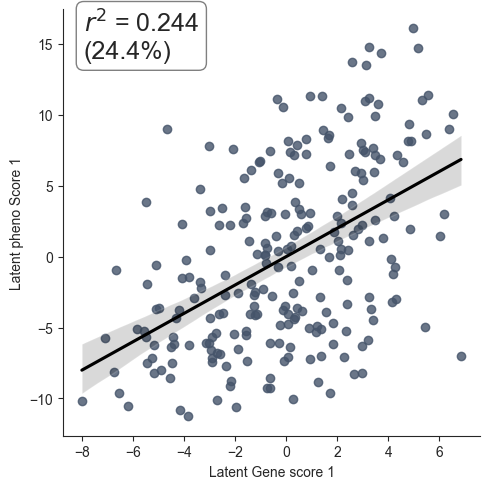

r2 = 0.2439791481947647, percent of total = 0.2439791481947647


<Figure size 500x400 with 0 Axes>

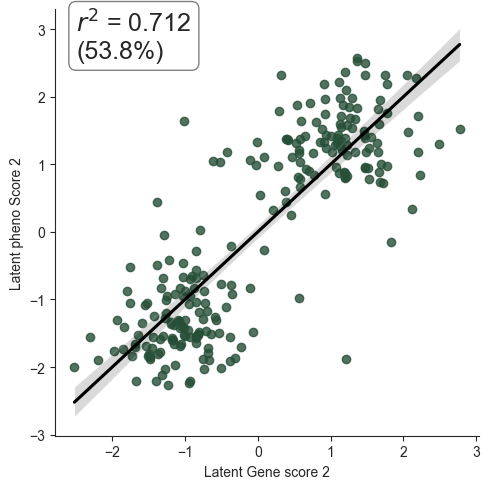

r2 = 0.7120326161399341, percent of total = 0.538311504967223


In [9]:
#make sure the data indexes are alligned
x_genes_train = pd.DataFrame(train_minmax, copy=True)
y_pheno_train = pd.DataFrame(pheno_minmax, copy=True)
x_genes_train, y_pheno_train = x_genes_train.align(y_pheno_train, join='inner', axis=0)

pls_mod = PLSRegression(n_components=2)
pls_mod.fit(x_genes_train,y_pheno_train)


# plot component scores
#sns.set_context('notebook', font_scale=1.5)
total = 1
leftover = 1

#make sure the data indexes are alligned
x_genes_train = pd.DataFrame(train_minmax, copy=True)
y_pheno_train = pd.DataFrame(pheno_minmax, copy=True)
x_genes_train, y_pheno_train = x_genes_train.align(y_pheno_train, join='inner', axis=0)

pls_mod = PLSRegression(n_components=2)
pls_mod.fit(x_genes_train,y_pheno_train)

# plot component scores
#sns.set_context('notebook', font_scale=1.5)
total = 1
leftover = 1
#pals = ['dark:#5A9_r', 'dark:#1f77b4_r']
#pals = ['dark:#2B6CB0', 'dark:#2B6CB0']
pals = ['#45546a', '#274f38']

# for each component
for i in range(pls_mod.n_components):
    # calculate local and overall explained variance
    r2 = stats.pearsonr(pls_mod.x_scores_[:, i], pls_mod.y_scores_[:, i])[0] ** 2
    explained = (leftover * r2)
    exp_perc = explained * 100

    # plot correlation between latent X (gene expression) and Y (space) components
    plt.close()
    # build plotting df
    plotr = pd.concat([pd.Series(pls_mod.x_scores_[:, i]),
                       pd.Series(pls_mod.y_scores_[:, i])],
                      axis=1)
    plotr.columns = ['x', 'y']

    # colors
    #cmap = sns.color_palette(pals[i], as_cmap=True)
    #sg = pls_mod.x_scores_[:, i]
    #scaled_sg = MinMaxScaler().fit_transform(sg.reshape(-1, 1))[:, 0]
    #norm = Normalize(vmin=np.min(scaled_sg),
    #                 vmax=np.max(scaled_sg))
    #cscale = cmap(norm(scaled_sg))
    
    point_color = pals[i]

    # plot
    plt.figure(figsize=(5, 4))  # Set the width and height (in inches)

    #g = sns.lmplot(x='x', y='y', data=plotr, scatter_kws={'color': cscale}, line_kws={'color': 'k'})
    g = sns.lmplot(x='x', y='y', data=plotr, scatter_kws={'color': point_color}, line_kws={'color': 'k'})
    
    # decorations
    plt.xlabel('Latent Gene score %i' % (i + 1))
    plt.ylabel('Latent pheno Score %i' % (i + 1))

    # Move text to the right of the graph
    plt.gca().text(0.05, 1,  # Adjusted coordinates (1.05 for right outside, 0.5 for center height)
                   f'$r^2$ = {round(r2, 3)}\n({round(exp_perc, 1)}%)',
                   transform=plt.gca().transAxes,
                   ha='left',                         # left-align horizontally
                   va='top',    
                   #horizontalalignment='left',  # Align text to the left
                   #verticalalignment='center',  # Center vertically
                   fontsize=18,  # Larger font size for readability
                   bbox=dict(boxstyle="round,pad=0.3", edgecolor="gray", facecolor="white"))  # Optional box
    plt.savefig(os.path.join(fig_dir, f'{plsset}_C%i_scoreplot.pdf' % (i + 1)), dpi=300, bbox_inches='tight')
    plt.show()
    print('r2 = %s, percent of total = %s' % (r2, explained))
    leftover -= explained


finished iteration 0
finished iteration 100
finished iteration 200
finished iteration 300
finished iteration 400
finished iteration 500
finished iteration 600
finished iteration 700
finished iteration 800
finished iteration 900


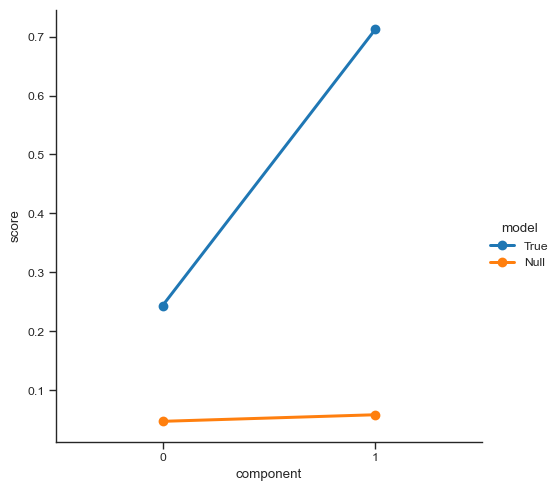

component 0: p = 0.001  ***
component 1: p = 0.001  ***


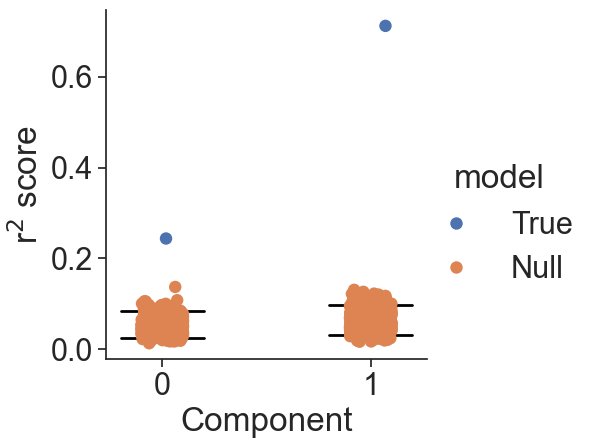

In [10]:
# Permutation and component evaluation
results, comp_sig, fig = evaluate_components(pls_mod, x_genes_train, y_pheno_train, n_iterations=1000)


# make that figure a bit more publication-ready
sns.set(font_scale=2)
sns.set_style('ticks')
g = sns.catplot(x='component', y='score', hue='model', data=results, s=80)
plt.ylabel('r$^2$ score')
plt.xlabel("Component")

for c in range(len(results.component.unique())):
    cvals = results[(results.component==c)&(results.model=='Null')
                ].score.sort_values().values
    cmin = cvals[25]
    cmax = cvals[975]
    plt.plot([c-.2,c+.2],[cmin,cmin],lw=2,c='black')
    plt.plot([c-.2,c+.2],[cmax,cmax],lw=2,c='black')
plt.savefig(os.path.join(fig_dir, f'{plsset}_Permutation_Comp_sig.pdf'), dpi=300, bbox_inches='tight')

## Bootstrapping

In [11]:
#make sure the data indexes are alligned
x_genes_train = pd.DataFrame(train_minmax, copy=True)
y_pheno_train = pd.DataFrame(pheno_minmax, copy=True)
x_genes_train, y_pheno_train = x_genes_train.align(y_pheno_train, join='inner', axis=0)

pls_mod = PLSRegression(n_components=2)
pls_mod.fit(x_genes_train,y_pheno_train)

plsx = pls_mod.x_scores_

In [12]:
# bootstrap iterations
n_iterations = 10000

# bootstrapping
bsrx, bsry, allx_bs, ally_bs = bootstrap_features(PLSRegression(n_components=2), 
                                                  pls_mod, 
                                                  x_genes_train, 
                                                  y_pheno_train, 
                                                  n_iterations=n_iterations,
                                                  mode='rotations')

finished iteration 0
finished iteration 100
finished iteration 200
finished iteration 300
finished iteration 400
finished iteration 500
finished iteration 600
finished iteration 700
finished iteration 800
finished iteration 900
finished iteration 1000
finished iteration 1100
finished iteration 1200
finished iteration 1300
finished iteration 1400
finished iteration 1500
finished iteration 1600
finished iteration 1700
finished iteration 1800
finished iteration 1900
finished iteration 2000
finished iteration 2100
finished iteration 2200
finished iteration 2300
finished iteration 2400
finished iteration 2500
finished iteration 2600
finished iteration 2700
finished iteration 2800
finished iteration 2900
finished iteration 3000
finished iteration 3100
finished iteration 3200
finished iteration 3300
finished iteration 3400
finished iteration 3500
finished iteration 3600
finished iteration 3700
finished iteration 3800
finished iteration 3900
finished iteration 4000
finished iteration 4100
fini

In [13]:
clus_labels = {
    'Excitatory_ExcL45RORBGABRG1_Cluster_0'  : 'Exc L4-5 RORB GABRG1 C0',
    'Excitatory_ExcL45RORBGABRG1_Cluster_7'  : 'Exc L4-5 RORB GABRG1 C7',
    'Excitatory_ExcL45RORBGABRG1_Cluster_8'  : 'Exc L4-5 RORB GABRG1 C8',
    'Excitatory_ExcL45RORBGABRG1_Cluster_13' : 'Exc L4-5 RORB GABRG1 C13',
    'Excitatory_ExcL45RORBGABRG1_Cluster_5'  : 'Exc L4-5 RORB GABRG1 C5',
    'Excitatory_ExcL45RORBGABRG1_Cluster_9'  : 'Exc L4-5 RORB GABRG1 C9',
    'Excitatory_ExcL45RORBGABRG1_Cluster_17' : 'Exc L4-5 RORB GABRG1 C17',

    'Excitatory_ExcL35RORBPLCH1_Cluster_14'  : 'Exc L3-5 RORB PLCH1 C14',
    'Excitatory_ExcL6CT_Cluster_14'          : 'Exc L6 CT C14',
    'Excitatory_ExcL34RORBCUX2_Cluster_6'    : 'Exc L3-4 RORB CUX2 C6',
    'Excitatory_ExcNRGN_Cluster_15'          : 'Exc NRGN C15',

    'Inhibitory_InhG7_Cluster_10'            : 'Inh G7 C10',
    'Inhibitory_InhG7_Cluster_12'            : 'Inh G7 C12',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1'  : 'Inh LAMP5 NRG1 Rosehip C1',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_12' : 'Inh LAMP5 NRG1 Rosehip C12',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_6'  : 'Inh LAMP5 NRG1 Rosehip C6',
    'Inhibitory_InhLAMP5NRG1Rosehip_Cluster_7'  : 'Inh LAMP5 NRG1 Rosehip C7',

    'OPCs_OPC_Cluster_16'                    : 'OPC C16',

    'Astrocytes_AstDPP10_Cluster_6'          : 'Ast DPP10 C6',

    'Oligodendrocytes_Oli_Cluster_12'        : 'Oli C12',
    'Oligodendrocytes_Oli_Cluster_3'         : 'Oli C3',

    'Immune_Micall_Cluster_11'               : 'Microglia C11',
    'Immune_Micall_Cluster_17'               : 'Microglia C17',
    'Immune_Micall_Cluster_0'                : 'Microglia C0'
}

## Get component loadings

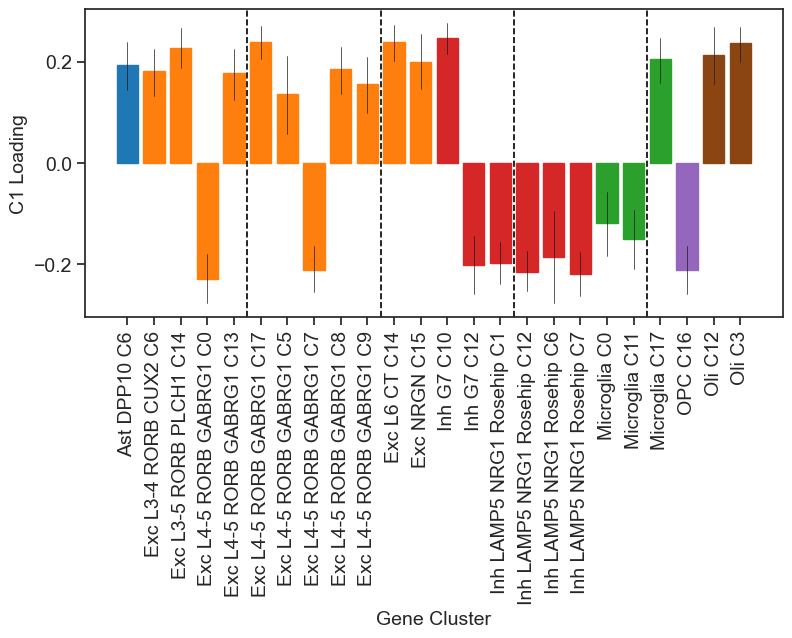

In [14]:
# C1 gene loadings
utils.plot_plsx_load(allx_bs, 
                     bsrx, 
                     x_genes_train.columns,
                     component=0,
                     pretty_labels=True,
                     cluster_label_map=clus_labels,
                     invert=False,
                     save=True,
                     file_name = "C1_gene_loadings.pdf",
                     out_dir=fig_dir)

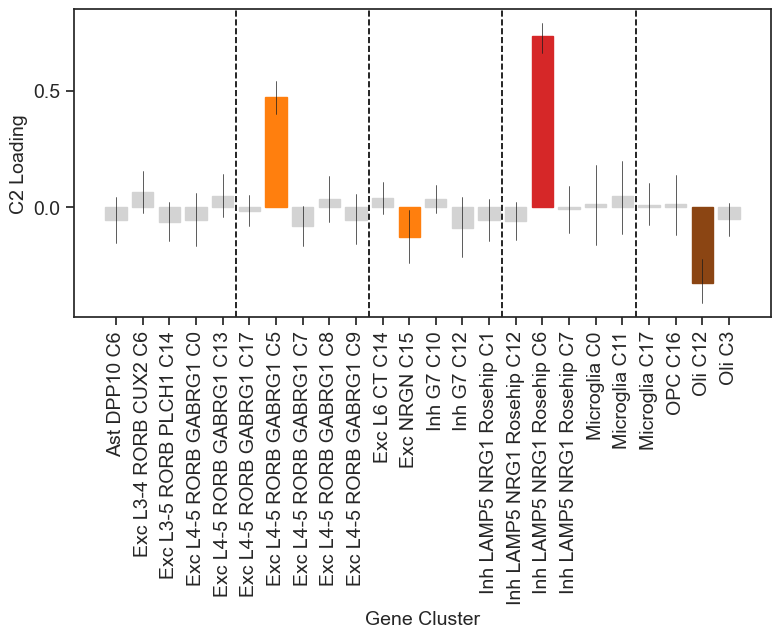

In [15]:
utils.plot_plsx_load(all_results_x=allx_bs,
                     x_feature_names=x_genes_train.columns, 
                     bs_stats_x=bsrx,
                     component=1,
                     pretty_labels=True,
                     cluster_label_map=clus_labels,
                     invert=False,
                     save=True,
                     file_name = "C2_gene_loadings.pdf",
                     out_dir=fig_dir)

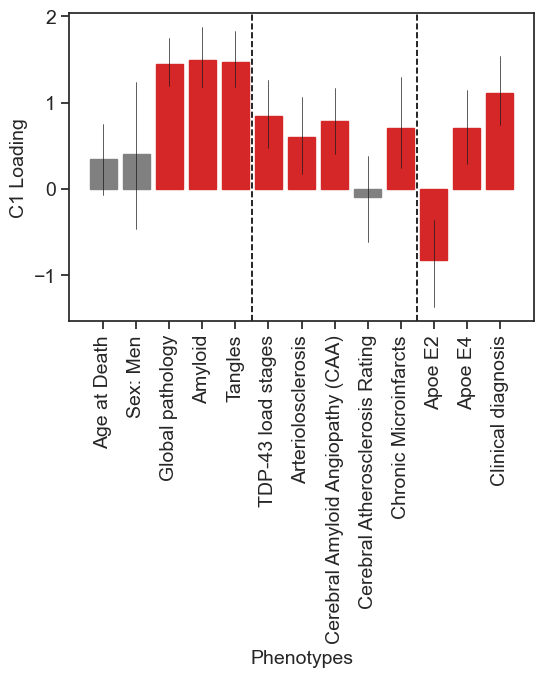

In [16]:
utils.plot_plsy_load(ally_bs, bsry, 
                     pheno_minmax.columns, 
                     component=0,
                     invert=False,
                     save=True,
                     file_name = "C1_yloadings.pdf",
                     out_dir=fig_dir)

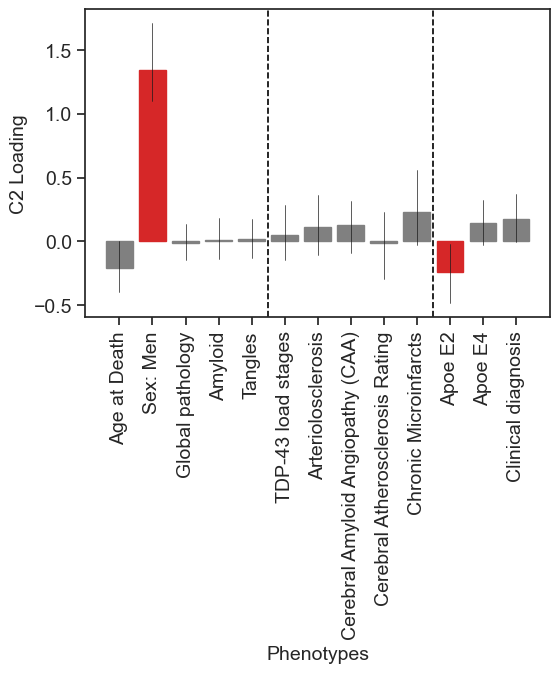

In [17]:
utils.plot_plsy_load(ally_bs, bsry, 
                     pheno_minmax.columns, 
                     component=1,
                     invert=False,
                     save=True,
                     file_name = "C2_yloadings.pdf",                     
                     out_dir=fig_dir)

In [18]:
### Export Component Loadings to CSV ####
INVERT_COMPONENTS = False 

components = (0, 1)   # 0=C1, 1=C2, 2=C3
alpha = 0.05

feature_names = list(y_pheno_train.columns)

# Grab bootstrap summaries for the components
mean_df = bsry["mean"].loc[list(components)].copy()
p_df    = bsry["p"].loc[list(components)].copy()

# Map bsrx columns (0..n-1) to actual gene cluster names
col_map = dict(zip(mean_df.columns, feature_names))
mean_df = mean_df.rename(columns=col_map)
p_df    = p_df.rename(columns=col_map)

if INVERT_COMPONENTS:
    mean_df = -mean_df


# Build wide table
# one row per cluster
out = pd.DataFrame({"phenotype": feature_names})

for comp in components:
    c = comp + 1
    out[f"C{c}_val"] = mean_df.loc[comp, feature_names].values
    out[f"C{c}_p"]   = p_df.loc[comp, feature_names].values
    out[f"C{c}_sig"] = out[f"C{c}_p"] < alpha

out.to_csv(os.path.join(files_dir, "PLSY_loadings_bsry_NORMALinv.csv"), index=False)

# PLS Scores Plots (Regression plots)

In [19]:
# Unscalling the pheno data for plotting
y_pheno_unscaled = pd.DataFrame(
    pheno_scaler.inverse_transform(y_pheno_train),
    columns=y_pheno_train.columns,
    index=y_pheno_train.index
)

In [20]:
# Build dataframe for plotting
df_plot = pd.DataFrame({
    "C1": plsx[:,0],
    "C2": plsx[:,1],
    "newcog_dx": y_pheno_unscaled["new_cogdx"].values,
    "tangles": y_pheno_unscaled["tangles"].values,
    "amyloid": y_pheno_unscaled["amyloid"].values,
    "gpath": y_pheno_unscaled["gpath"].values,
    "tdp": y_pheno_unscaled["tdp_st4"].values,
    "arteriol_scler": y_pheno_unscaled["arteriol_scler"],
    "sex": y_pheno_unscaled["msex"].map({1: "Male", 0: "Female"}),
    "E4": y_pheno_unscaled['E4'].map({0.0: 'No copies', 1.0: 'E4', 2.0: 'E4'}),
    "E2": y_pheno_unscaled['E2'].map({0.0: 'No copies', 1.0: 'E2', 2.0: 'E2'}),
    "Microinf": y_pheno_unscaled['ci_num2_mct'],
    "CAA": y_pheno_unscaled['caa_4gp'],
    "AgeDeath": y_pheno_unscaled['age_death'].values
})

df_plot.to_csv(os.path.join(files_dir, "PLSX_scores_pheno.csv"))

In [21]:
plt.rcParams.update({
    'axes.labelsize': 16,   # X and Y label font size
    'xtick.labelsize': 14,  # X-tick font size
    'ytick.labelsize': 14,  # Y-tick font size
    'legend.fontsize': 17,  # Legend font size
    'font.size': 16 ,        # General font size
    'figure.figsize': (3,3)
})

## C1

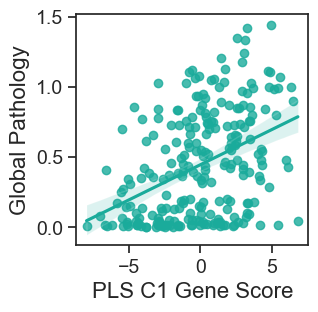

r = 0.410, R² = 0.168, p = 4.49e-11


In [23]:
# Global Pathology ~ C1
sns.regplot(x=df_plot['C1'], y=df_plot['gpath'],lowess=False, color=COLORS["c1_green"])
plt.xlabel('PLS C1 Gene Score')
plt.ylabel('Global Pathology')
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_gpath.pdf'), dpi=300, bbox_inches='tight')
plt.show()

x = df_plot['C1']
y = df_plot['gpath'].values

r, p = stats.pearsonr(x, y)
r2 = r**2
print(f"r = {r:.3f}, R² = {r2:.3f}, p = {p:.2e}")

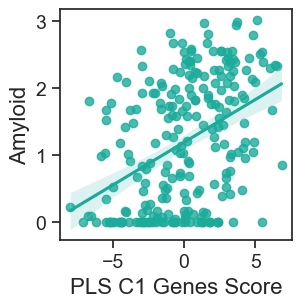

r = 0.417, R² = 0.174, p = 1.99e-11


In [24]:
# Amyloid ~ C1
sns.regplot(x=df_plot['C1'], y=df_plot['amyloid'],lowess=False,color=COLORS["c1_green"])
plt.xlabel('PLS C1 Genes Score')
plt.ylabel('Amyloid')

plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_amyloid.pdf'), dpi=300, bbox_inches='tight')
plt.show()

x = df_plot['C1']
y = df_plot['amyloid'].values

r, p = stats.pearsonr(x, y)
r2 = r**2
print(f"r = {r:.3f}, R² = {r2:.3f}, p = {p:.2e}")

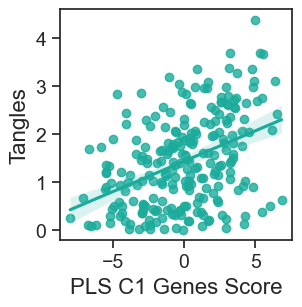

r = 0.414, R² = 0.172, p = 2.74e-11


In [25]:
# Tangles ~ C1
sns.regplot(x=df_plot['C1'], y=df_plot['tangles'],lowess=False,color=COLORS["c1_green"])
plt.xlabel('PLS C1 Genes Score')
plt.ylabel('Tangles')
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_tangles.pdf'), dpi=300, bbox_inches='tight')
plt.show()

x = df_plot['C1']
y = df_plot['tangles'].values

r, p = stats.pearsonr(x, y)
r2 = r**2
print(f"r = {r:.3f}, R² = {r2:.3f}, p = {p:.2e}")


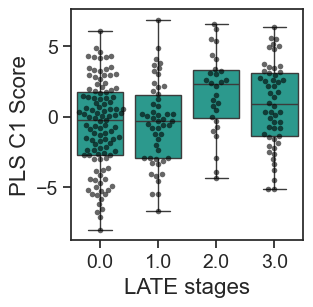

In [26]:
# LATE boxplot
sns.boxplot(x=df_plot['tdp'],y=df_plot['C1'],color=COLORS["c1_green"])
sns.swarmplot(x=df_plot['tdp'], y=df_plot['C1'], size=4, alpha=0.6, color='black')

plt.xlabel("LATE stages")
plt.ylabel("PLS C1 Score")
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_TDP43.pdf'), dpi=300, bbox_inches='tight')
plt.show()

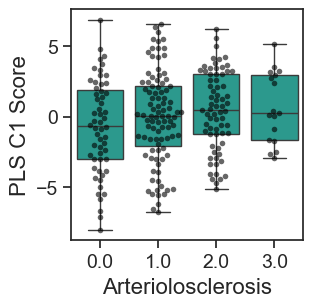

In [27]:
# Arteriolo sclerosis boxplot
sns.boxplot(x=df_plot['arteriol_scler'], y=df_plot['C1'],color=COLORS["c1_green"])
sns.swarmplot(x=df_plot['arteriol_scler'], y=df_plot['C1'], size=4, alpha=0.6, color='black')

plt.xlabel("Arteriolosclerosis")
plt.ylabel("PLS C1 Score")
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_arterioslosclerosis.pdf'), dpi=300, bbox_inches='tight')
plt.show()

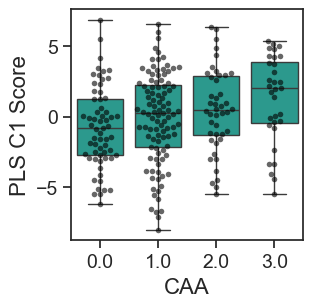

In [28]:
# Arteriolo sclerosis boxplot
sns.boxplot(x=df_plot['CAA'],y=df_plot['C1'],color=COLORS["c1_green"])
sns.swarmplot(x=df_plot['CAA'], y=df_plot['C1'], size=4, alpha=0.6, color='black')
plt.xlabel("CAA")
plt.ylabel("PLS C1 Score")
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_CAA.pdf'), dpi=300, bbox_inches='tight')
plt.show()

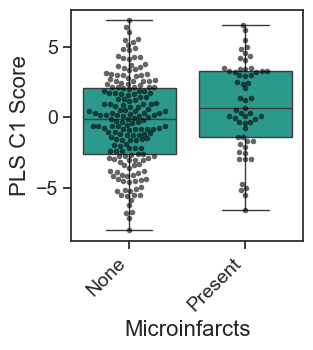

In [29]:
# Microinfarcts boxplot
sns.boxplot(x=df_plot['Microinf'].map({0: 'None', 1:'Present'}), y=df_plot['C1'], color=COLORS["c1_green"], order=["None", "Present"])
sns.swarmplot(x=df_plot['Microinf'].map({0: 'None', 1:'Present'}), y=df_plot['C1'], size=4, alpha=0.6, color='black', order=["None", "Present"])
plt.xlabel("Microinfarcts")
plt.ylabel("PLS C1 Score")
plt.xticks(rotation=45, ha='right')
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_Microinf.pdf'), dpi=300, bbox_inches='tight')
plt.show()

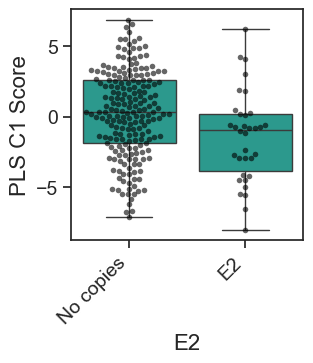

In [30]:
# E2 boxplot
sns.boxplot(x=df_plot['E2'], y=df_plot['C1'],color=COLORS["c1_green"])
sns.swarmplot(x=df_plot['E2'], y=df_plot['C1'], size=4, alpha=0.6, color='black')

plt.xlabel("E2")
plt.ylabel("PLS C1 Score")
plt.xticks(rotation=45, ha='right')
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_E2.pdf'), dpi=300, bbox_inches='tight')
plt.show()

In [31]:
from scipy import stats

e2_df = df_plot[["C1", "E2"]].dropna().copy()

noncarriers = e2_df.loc[e2_df["E2"] == "No copies", "C1"]
carriers = e2_df.loc[e2_df["E2"] == "E2", "C1"]

t_stat, p_value = stats.ttest_ind(
    carriers,
    noncarriers,
    equal_var=False  # Welch's t-test
)

print(f"Non-carriers: n={len(noncarriers)}, mean={noncarriers.mean():.3f}")
print(f"E2 carriers: n={len(carriers)}, mean={carriers.mean():.3f}")
print(f"Welch's t = {t_stat:.3f}, p = {p_value:.3e}")
print(f"Mean difference = {carriers.mean() - noncarriers.mean():.3f}")

Non-carriers: n=204, mean=0.242
E2 carriers: n=34, mean=-1.449
Welch's t = -2.879, p = 6.159e-03
Mean difference = -1.691


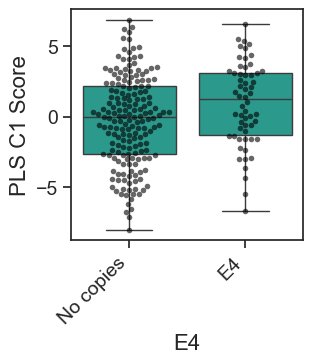

In [32]:
# E4 boxplot
sns.boxplot(x=df_plot['E4'], y=df_plot['C1'],color=COLORS["c1_green"])
sns.swarmplot(x=df_plot['E4'], y=df_plot['C1'], size=4, alpha=0.6, color='black')
plt.xlabel("E4")
plt.ylabel("PLS C1 Score")
plt.xticks(rotation=45, ha='right')
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_E4.pdf'), dpi=300, bbox_inches='tight')
plt.show()

In [33]:
from scipy import stats

e2_df = df_plot[["C1", "E4"]].dropna().copy()

noncarriers = e2_df.loc[e2_df["E4"] == "No copies", "C1"]
carriers = e2_df.loc[e2_df["E4"] == "E4", "C1"]

t_stat, p_value = stats.ttest_ind(
    carriers,
    noncarriers,
    equal_var=False  # Welch's t-test
)

print(f"Non-carriers: n={len(noncarriers)}, mean={noncarriers.mean():.3f}")
print(f"E4 carriers: n={len(carriers)}, mean={carriers.mean():.3f}")
print(f"Welch's t = {t_stat:.3f}, p = {p_value:.3e}")
print(f"Mean difference = {carriers.mean() - noncarriers.mean():.3f}")

Non-carriers: n=180, mean=-0.296
E4 carriers: n=58, mean=0.918
Welch's t = 2.702, p = 8.074e-03
Mean difference = 1.214


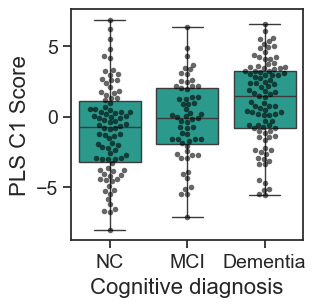

In [34]:
# Microinfarcts boxplot
#sns.boxplot(x=df_plot['newcog_dx'] , y=df_plot['C1'],color=COLORS["c1_green"])

sns.boxplot(x=df_plot['newcog_dx'].map({1.0:'NC', 2.0:"MCI", 3.0:"Dementia"}),
            order = ['NC', 'MCI', 'Dementia'],
            y=df_plot['C1'],
            color=COLORS["c1_green"])

sns.swarmplot(x=df_plot['newcog_dx'].map({1.0:'NC', 2.0:"MCI", 3.0:"Dementia"}),
            order = ['NC', 'MCI', 'Dementia'],
            y=df_plot['C1'], size=4, alpha=0.6, color='black')

plt.xlabel("Cognitive diagnosis")
plt.ylabel("PLS C1 Score")
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX1_Cogdx.pdf'), dpi=300, bbox_inches='tight')
plt.show()

In [35]:
import pandas as pd
import pingouin as pg

diag_df = (
    df_plot.loc[
        df_plot["newcog_dx"].isin([1.0, 2.0, 3.0]),
        ["C1", "newcog_dx"]
    ]
    .dropna()
    .copy()
)

diag_df["Diagnosis"] = diag_df["newcog_dx"].map({
    1.0: "NC",
    2.0: "MCI",
    3.0: "Dementia"
})

diag_df["Diagnosis"] = pd.Categorical(
    diag_df["Diagnosis"],
    categories=["NC", "MCI", "Dementia"],
    ordered=True
)

# Descriptive statistics
summary = (
    diag_df.groupby("Diagnosis", observed=False)["C1"]
    .agg(["count", "mean", "std", "median"])
)

print(summary)

# Omnibus test: does C1 differ among any of the three groups?
welch_results = pg.welch_anova(
    data=diag_df,
    dv="C1",
    between="Diagnosis"
)

print("\nWelch ANOVA:")
print(welch_results)

# Post-hoc tests: which groups differ?
posthoc_results = pg.pairwise_gameshowell(
    data=diag_df,
    dv="C1",
    between="Diagnosis"
)

print("\nGames–Howell pairwise comparisons:")
print(posthoc_results)

           count      mean       std    median
Diagnosis                                     
NC            86 -0.962279  3.172544 -0.718193
MCI           59 -0.263076  2.833833 -0.126682
Dementia      93  1.056747  2.924330  1.430847

Welch ANOVA:
      Source  ddof1       ddof2          F     p_unc       np2
0  Diagnosis      2  145.249178  10.202135  0.000071  0.081708

Games–Howell pairwise comparisons:
     A         B    mean_A    mean_B      diff        se         T  \
0   NC       MCI -0.962279 -0.263076 -0.699203  0.503137 -1.389686   
1   NC  Dementia -0.962279  1.056747 -2.019025  0.457153 -4.416517   
2  MCI  Dementia -0.263076  1.056747 -1.319822  0.477562 -2.763664   

           df      pval    hedges  
0  133.350090  0.349182 -0.228814  
1  172.598781  0.000052 -0.660020  
2  126.453354  0.017923 -0.454450  


## C2

/opt/anaconda3/envs/SEAADpy/lib/python3.12/site-packages/seaborn/categorical.py:3399: UserWarning: 5.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


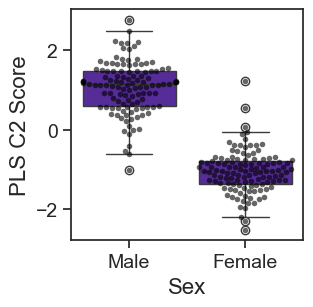

In [36]:
# Sex boxplot
sns.boxplot(x=df_plot['sex'], y=df_plot['C2'],color=COLORS["c2_purple"])
sns.swarmplot(x=df_plot['sex'], y=df_plot['C2'], size=4, alpha=0.6, color='black')

plt.xlabel("Sex")
plt.ylabel("PLS C2 Score")
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX2_Sex.pdf'), dpi=300, bbox_inches='tight')
plt.show()

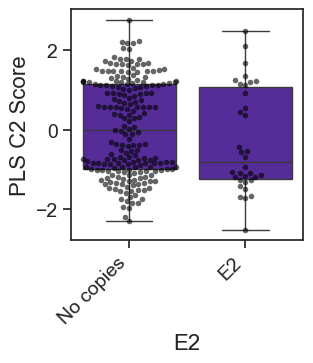

In [37]:
# E2 boxplot
sns.boxplot(x=df_plot['E2'], y=df_plot['C2'],color=COLORS["c2_purple"])
sns.swarmplot(x=df_plot['E2'], y=df_plot['C2'], size=4, alpha=0.6, color='black')

plt.xlabel("E2")
plt.ylabel("PLS C2 Score")
plt.xticks(rotation=45, ha='right')
plt.savefig(os.path.join(fig_dir, f'{plsset}_reg_PLSX2_E2.pdf'), dpi=300, bbox_inches='tight')
plt.show()